In [1]:
from torchvision.datasets import OxfordIIITPet

In [2]:
from google.colab import drive
import torch
import torch.nn as nn
from torchvision import models, transforms

# 1. Inisialisasi Model & Ekstraksi Bobot Pretrained
weights = models.ResNet18_Weights.IMAGENET1K_V1
model = models.resnet18(weights=weights)

# 2. Konfigurasi B2: Feature Extraction (Bekukan Backbone)
for param in model.parameters():
  param.requires_grad = False

# Ganti classifier head untuk 10 kelas
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, 10)

# 3. Konfigurasi B3: Unfreeze Blok Residual Terakhir (layer4)
# for param in model.layer4.parameters():
#   param.requires_grad = True

# Optimasi dengan Differential Learning Rate
optimizer = torch.optim.AdamW([
  {"params": model.layer4.parameters(),  "lr": 1e-4},
  {"params": model.fc.parameters(),      "lr": 1e-3},
], weight_decay=1e-2)

# 4. Pipeline Transformasi Data
# Data latih: menerapkan augmentasi aktif
train_transforms = transforms.Compose([
  transforms.Resize(256),
  transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
  transforms.RandomHorizontalFlip(p=0.5),
  transforms.RandomRotation(degrees=15),
  transforms.ColorJitter(brightness=0.2, contrast=0.2),
  transforms.ToTensor(),
  transforms.Normalize(mean=weights.transforms().mean, std=weights.transforms().std),
])

# Data validasi/uji: hanya deterministik tanpa distorsi
eval_transforms = weights.transforms()

# Verifikasi parameter yang dapat dilatih
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in model.parameters())
print(f"Trainable Parameters: {trainable_params:,} / {total_params:,}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 164MB/s]


Trainable Parameters: 5,130 / 11,181,642


In [3]:
import copy, json, os, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset, DataLoader

SEED = 42
BATCH_SIZE = 32
MAX_EPOCHS = 30
PATIENCE = 5
device = "cuda" if torch.cuda.is_available() else "cpu"
drive.mount('/content/drive')
OUT = "/content/drive/MyDrive/tugas05_outputs"
os.makedirs(f"{OUT}/models", exist_ok=True)

def set_seed():
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

set_seed()

Mounted at /content/drive


In [4]:
import os


data_dir = '/content/drive/MyDrive/datasets'

raw = [OxfordIIITPet(root=data_dir, split=s, download=True) for s in ("trainval", "test")]

In [5]:
classes = ["Abyssinian", "Bengal", "Birman", "Bombay", "British Shorthair", "Beagle", "Boxer", "Chihuahua", "Pug", "Samoyed"]

all_names = raw[0].classes
assert all(c in all_names for c in classes), f"check class names: {all_names}"
label_map = {all_names.index(c): i for i, c in enumerate(classes)}

paths, labels = [], []
for ds in raw:
    for path, label in zip(ds._images, ds._labels):
        if label in label_map:
            paths.append(str(path))
            labels.append(label_map[label])
paths, labels = np.array(paths), np.array(labels)

all_idx = np.arange(len(labels))
train_idx, rest_idx = train_test_split(all_idx, test_size=0.30, stratify=labels, random_state=SEED)
val_idx, test_idx = train_test_split(rest_idx, test_size=0.50, stratify=labels[rest_idx], random_state=SEED)
print(f"train={len(train_idx)}  val={len(val_idx)}  test={len(test_idx)}")
np.savez(f"{OUT}/split.npz", train_idx=train_idx, val_idx=val_idx, test_idx=test_idx, labels=labels)
json.dump(classes, open(f"{OUT}/classes.json", "w"))


class PetDataset(Dataset):
    def __init__(self, idx, transform):
        self.idx = idx
        self.transform = transform

    def __len__(self):
        return len(self.idx)

    def __getitem__(self, i):
        j = self.idx[i]
        image = Image.open(paths[j]).convert("RGB")
        return self.transform(image), int(labels[j])


def get_loader(idx, transform, shuffle=False):
    return DataLoader(PetDataset(idx, transform), batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=2, persistent_workers=True)


train=1386  val=297  test=298


In [6]:
def get_model(arch, mode):
    set_seed()

    if arch == "resnet18":
        model = models.resnet18(weights=None if mode == "scratch" else weights)
        model.fc = nn.Linear(512, 10)
        head, last_block = model.fc, model.layer4
    else:  # efficientnet_b0
        model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
        model.classifier[1] = nn.Linear(1280, 10)
        head, last_block = model.classifier, model.features[7:]

    if mode == "scratch":
        return model, [{"params": model.parameters(), "lr": 1e-3}]

    for p in model.parameters():
        p.requires_grad = False
    for p in head.parameters():
        p.requires_grad = True
    groups = [{"params": head.parameters(), "lr": 1e-3}]

    if mode == "finetune":
        for p in last_block.parameters():
            p.requires_grad = True
        groups.append({"params": last_block.parameters(), "lr": 1e-4})

    return model, groups

# TRAINING

In [7]:
from tqdm.auto import tqdm

In [8]:
loss_fn = nn.CrossEntropyLoss()
results = []     # one row per experiment
history = []     # one row per epoch
test_probs = {}  # saved for the failure analysis


def evaluate(model, loader):
    model.eval()
    total_loss, all_probs, all_labels = 0, [], []
    with torch.no_grad():
        for x, y in loader:
            out = model(x.to(device))
            total_loss += loss_fn(out, y.to(device)).item() * len(y)
            all_probs.append(out.softmax(1).cpu())
            all_labels.append(y)
    probs = torch.cat(all_probs).numpy()
    y_true = torch.cat(all_labels).numpy()
    acc = (probs.argmax(1) == y_true).mean()
    return total_loss / len(y_true), acc, probs, y_true


def train(name, arch, mode, augment=True):
    model, groups = get_model(arch, mode)
    model.to(device)

    n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    n_total = sum(p.numel() for p in model.parameters())
    lrs = [g["lr"] for g in groups]
    print(f"\n=== {name} | trainable {n_trainable:,} / {n_total:,} | lr {lrs} ===")
    if arch == "resnet18" and mode == "feature":
        assert n_trainable == 5130

    optimizer = torch.optim.AdamW(groups, weight_decay=1e-2)
    train_loader = get_loader(train_idx, train_transforms if augment else eval_transforms, shuffle=True)
    val_loader = get_loader(val_idx, eval_transforms)

    best_loss, best_epoch, best_weights, bad_epochs = float("inf"), 0, None, 0
    start = time.time()

    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        for m in model.modules():          # frozen BatchNorm stays in eval mode
            if isinstance(m, nn.BatchNorm2d) and not m.weight.requires_grad:
                m.eval()

        loss_sum, correct = 0, 0
        for x, y in tqdm(train_loader, desc=f"{name} epoch {epoch}/{MAX_EPOCHS}", leave=False):
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = loss_fn(out, y)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * len(y)
            correct += (out.argmax(1) == y).sum().item()

        train_loss, train_acc = loss_sum / len(train_idx), correct / len(train_idx)
        val_loss, val_acc, _, _ = evaluate(model, val_loader)
        history.append(dict(run=name, epoch=epoch, train_loss=train_loss, train_acc=train_acc,
                            val_loss=val_loss, val_acc=val_acc))
        print(f"epoch {epoch:2d} | train {train_loss:.4f} ({train_acc:.3f}) | val {val_loss:.4f} ({val_acc:.3f})")

        # early stopping on validation loss
        if val_loss < best_loss:
            best_loss, best_epoch = val_loss, epoch
            best_weights = copy.deepcopy(model.state_dict())
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs == PATIENCE:
                print("early stopping")
                break

    train_time = time.time() - start
    model.load_state_dict(best_weights)

    # final numbers from the best epoch
    val_loss, val_acc, _, _ = evaluate(model, val_loader)
    _, train_acc_clean, _, _ = evaluate(model, get_loader(train_idx, eval_transforms))  # no augmentation
    _, test_acc, probs, y_true = evaluate(model, get_loader(test_idx, eval_transforms))
    test_f1 = f1_score(y_true, probs.argmax(1), average="macro")

    results.append(dict(
        run=name, arch=arch, mode=mode, augment=augment, seed=SEED,
        trainable_params=n_trainable, lr=str(lrs),
        best_epoch=best_epoch, epochs_run=epoch, train_time_s=round(train_time, 1),
        train_acc=round(train_acc_clean, 4), val_acc=round(val_acc, 4),
        gap=round(train_acc_clean - val_acc, 4),
        test_acc=round(test_acc, 4), test_macro_f1=round(test_f1, 4),
    ))
    test_probs[name] = probs

    torch.save(model.state_dict(), f"{OUT}/models/{name}.pt")   # best-epoch weights
    np.save(f"{OUT}/models/{name}_test_probs.npy", probs)

    # save after every run so nothing is lost if Colab disconnects
    pd.DataFrame(results).to_csv(f"{OUT}/results.csv", index=False)
    json.dump(results, open(f"{OUT}/results.json", "w"), indent=2)
    pd.DataFrame(history).to_csv(f"{OUT}/history.csv", index=False)

In [ ]:
train("B1_scratch",            "resnet18", "scratch")
train("B2_feature_extraction", "resnet18", "feature")
train("B3_finetune_layer4",    "resnet18", "finetune")
train("B4_finetune_no_aug",    "resnet18", "finetune", augment=False)

# B5: same strategy as the better of B2 / B3 (chosen on validation accuracy)
r = {x["run"]: x for x in results}
best_mode = "finetune" if r["B3_finetune_layer4"]["val_acc"] >= r["B2_feature_extraction"]["val_acc"] else "feature"
train("B5_efficientnet_b0", "efficientnet_b0", best_mode)

table = pd.DataFrame(results)
print(table.to_string(index=False))


=== B1_scratch | trainable 11,181,642 / 11,181,642 | lr [0.001] ===


B1_scratch epoch 1/30:   0%|          | 0/44 [00:00<?, ?it/s]

epoch  1 | train 2.2902 (0.212) | val 2.5173 (0.232)


B1_scratch epoch 2/30:   0%|          | 0/44 [00:00<?, ?it/s]

epoch  2 | train 2.0000 (0.285) | val 3.2796 (0.242)


...

epoch  6 | train 0.0490 (0.990) | val 0.0671 (0.987)


B5_efficientnet_b0 epoch 7/30:   0%|          | 0/44 [00:00<?, ?it/s]

epoch  7 | train 0.0387 (0.990) | val 0.0712 (0.987)


B5_efficientnet_b0 epoch 8/30:   0%|          | 0/44 [00:00<?, ?it/s]

epoch  8 | train 0.0336 (0.992) | val 0.0715 (0.990)
early stopping
                  run            arch     mode  augment  seed  trainable_params              lr  best_epoch  epochs_run  train_time_s  train_acc  val_acc    gap  test_acc  test_macro_f1
           B1_scratch        resnet18  scratch     True    42          11181642         [0.001]           9          14         273.0     0.5115   0.4714 0.0402    0.4799         0.4548
B2_feature_extraction        resnet18  feature     True    42              5130         [0.001]          11          16         303.7     0.9841   0.9697 0.0144    0.9664         0.9666
   B3_finetune_layer4        resnet18 finetune     True    42           8398858 [0.001, 0.0001]           4           9         166.6     0.9971   0.9697 0.0274    0.9698         0.9698
   B4_finetune_no_aug        resnet18 finetune    False    42           8398858 [0.001, 0.0001]           6          11         155.3     1.0000   0.9764 0.0236    0.9799         0.9798
  

# LOSS CURVES

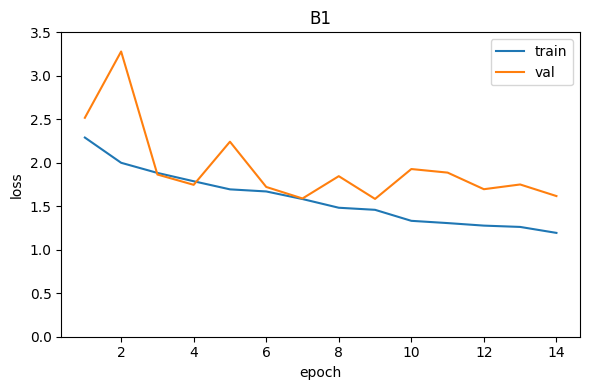

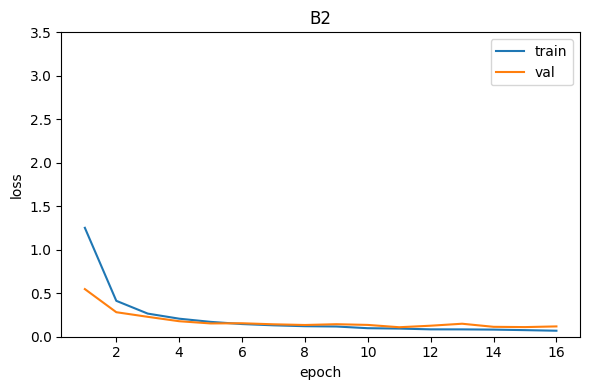

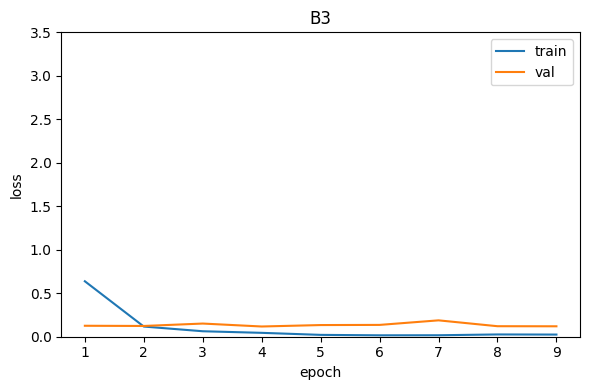

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

hist = pd.read_csv(f"{OUT}/history.csv")

for name, title in [("B1_scratch", "B1"), ("B2_feature_extraction", "B2"), ("B3_finetune_layer4", "B3")]:
    h = hist[hist.run == name]

    plt.figure(figsize=(6, 4))
    plt.plot(h.epoch, h.train_loss, label="train")
    plt.plot(h.epoch, h.val_loss, label="val")
    plt.title(title)
    plt.xlabel("epoch")
    plt.ylabel("loss")
    plt.ylim(0, 3.5)
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"{OUT}/loss_curve_{title}.png", dpi=150)
    plt.show()

best model: B5_efficientnet_b0, showing 5 mistakes


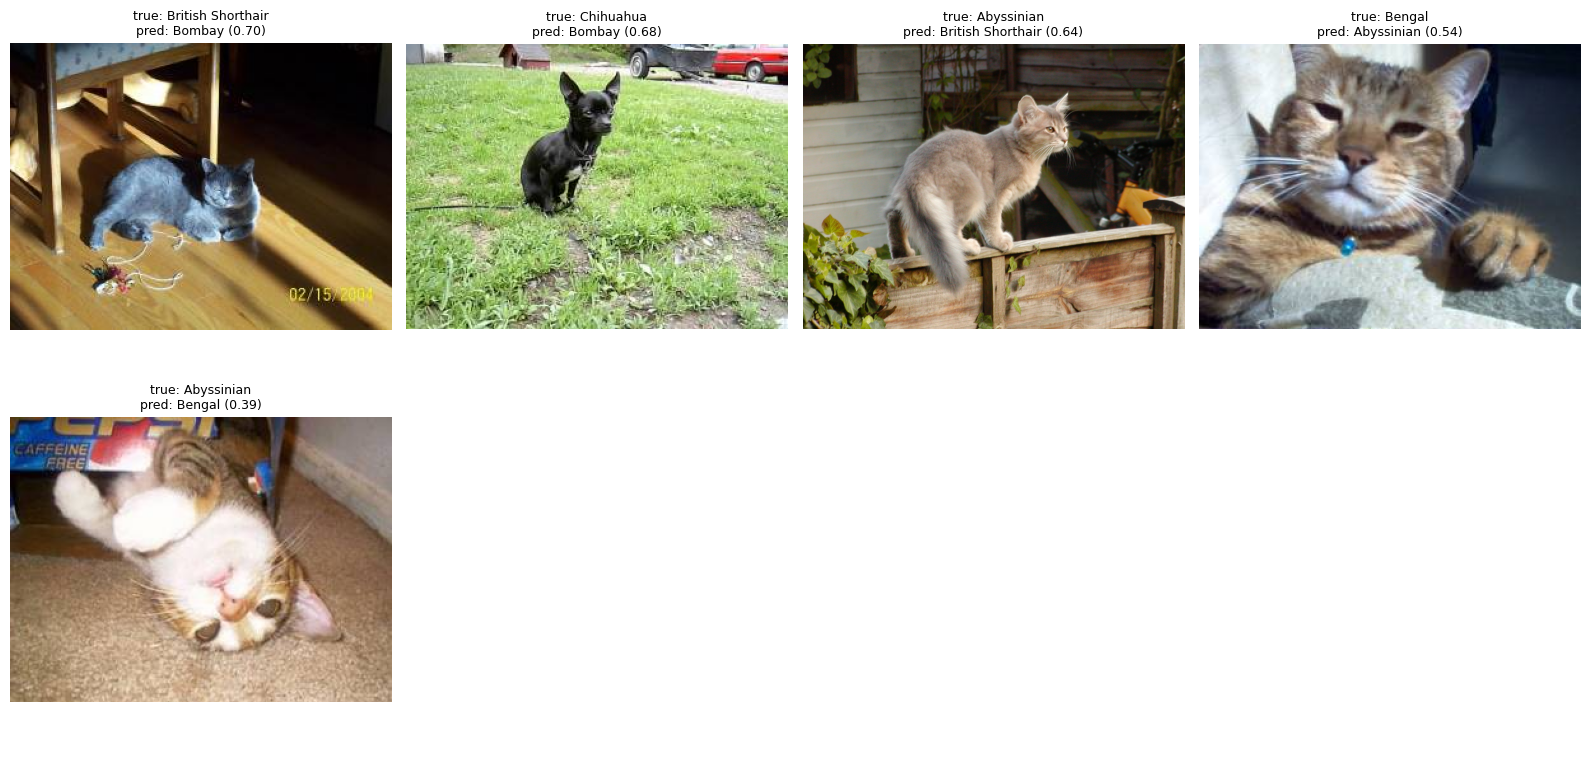

In [ ]:
best_name = table.sort_values("test_macro_f1").iloc[-1]["run"]
probs = test_probs[best_name]
pred = probs.argmax(1)
truth = labels[test_idx]

wrong = np.where(pred != truth)[0]
wrong = wrong[np.argsort(-probs[wrong].max(1))][:8]   # most confident mistakes first
print(f"best model: {best_name}, showing {len(wrong)} mistakes")

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax in axes.ravel():
    ax.axis("off")
for ax, k in zip(axes.ravel(), wrong):
    ax.imshow(Image.open(paths[test_idx[k]]).convert("RGB"))
    ax.set_title(f"true: {classes[truth[k]]}\npred: {classes[pred[k]]} ({probs[k].max():.2f})", fontsize=9)
plt.tight_layout()
plt.savefig(f"{OUT}/failure_analysis.png", dpi=150)
plt.show()